# Task 1.1
## a. Variante con espera (M/M/c)
Con base en los parÃ¡metros calculados para el Grupo 1 ($\lambda = 3.0$, $c = 17$), calcularemos el desempeÃ±o teÃ³rico asumiendo que los pacientes esperan en urgencias si no hay camas. El cÃ³digo evalÃºa la carga ofrecida ($a$), la utilizaciÃ³n ($\rho$), la probabilidad de esperar usando la fÃ³rmula C de Erlang, y las mÃ©tricas de espera en la cola ($L_q$, $W_q$) y en el sistema completo ($W$). Los tiempos se convierten a horas para facilitar la interpretaciÃ³n.

In [5]:
import math

# ParÃ¡metros del Grupo 1
lam = 3.0      # Tasa de llegadas (pacientes/dÃ­a)
mu = 0.25      # Tasa de servicio (pacientes/dÃ­a)
c = 17         # NÃºmero de camas

# CÃ¡lculos bÃ¡sicos
a = lam / mu   # Carga ofrecida (Erlangs)
rho = a / c    # UtilizaciÃ³n

# FunciÃ³n para calcular la probabilidad de esperar (Erlang C)
def erlang_c(c, a):
    rho = a / c
    # CÃ¡lculo del numerador
    numerador = (a**c) / (math.factorial(c) * (1 - rho))
    
    # CÃ¡lculo del denominador (sumatoria)
    sumatoria = sum([(a**n) / math.factorial(n) for n in range(c)])
    denominador = sumatoria + numerador
    
    return numerador / denominador

# Probabilidad de esperar
prob_esperar = erlang_c(c, a)

# NÃºmero promedio en cola (Lq)
Lq = prob_esperar * (rho / (1 - rho))

# Tiempos (Wq y W) en dÃ­as y luego en horas
Wq_dias = Lq / lam
Wq_horas = Wq_dias * 24

W_dias = Wq_dias + (1 / mu)
W_horas = W_dias * 24

print("--- Variante con espera (M/M/c) ---")
print(f"Carga ofrecida (a): {a} Erlangs")
print(f"UtilizaciÃ³n (rho): {rho:.4f} ({rho*100:.2f}%)")
print(f"Probabilidad de esperar C(c,a): {prob_esperar:.4f} ({prob_esperar*100:.2f}%)")
print(f"NÃºmero promedio en cola (Lq): {Lq:.4f} pacientes")
print(f"Tiempo promedio en cola (Wq): {Wq_horas:.4f} horas")
print(f"Tiempo promedio en el sistema (W): {W_horas:.4f} horas")

--- Variante con espera (M/M/c) ---
Carga ofrecida (a): 12.0 Erlangs
UtilizaciÃ³n (rho): 0.7059 (70.59%)
Probabilidad de esperar C(c,a): 0.1266 (12.66%)
NÃºmero promedio en cola (Lq): 0.3039 pacientes
Tiempo promedio en cola (Wq): 2.4313 horas
Tiempo promedio en el sistema (W): 98.4313 horas


## b. Variante sin espera (M/M/c/c)
Calculamos el desempeÃ±o asumiendo que los pacientes que no encuentran cama son desviados a otro centro. Utilizamos la relaciÃ³n de recurrencia de Erlang para la probabilidad de bloqueo ($B$), lo que nos permite calcular la tasa efectiva de ingresos ($\lambda_{eff}$) y el nÃºmero promedio de camas ocupadas ($L$).

In [6]:
# FunciÃ³n para calcular la probabilidad de bloqueo (Erlang B) por recurrencia
def erlang_b(c, a):
    b = 1.0
    for k in range(1, c + 1):
        b = (a * b) / (k + a * b)
    return b

# Probabilidad de bloqueo
prob_bloqueo = erlang_b(c, a)

# Tasa efectiva de ingresos
lam_eff = lam * (1 - prob_bloqueo)

# NÃºmero promedio de camas ocupadas
L_sin_espera = lam_eff / mu

print("\n--- Variante sin espera (M/M/c/c) ---")
print(f"Probabilidad de bloqueo B(c,a): {prob_bloqueo:.4f} ({prob_bloqueo*100:.2f}%)")
print(f"Tasa efectiva de ingresos (lambda_eff): {lam_eff:.4f} pacientes/dÃ­a")
print(f"NÃºmero promedio de camas ocupadas (L): {L_sin_espera:.4f} camas")


--- Variante sin espera (M/M/c/c) ---
Probabilidad de bloqueo B(c,a): 0.0409 (4.09%)
Tasa efectiva de ingresos (lambda_eff): 2.8773 pacientes/dÃ­a
NÃºmero promedio de camas ocupadas (L): 11.5092 camas


## c. VerificaciÃ³n con la Ley de Little
La Ley de Little dicta que el nÃºmero de entidades en el sistema es el producto de la tasa de llegada y el tiempo de permanencia ($L = \lambda W$)[cite: 1]. Se verifica la consistencia en ambas variantes para comprobar que no existan errores matemÃ¡ticos en las mÃ©tricas.

In [7]:
print("\n--- VerificaciÃ³n Ley de Little ---")

# VerificaciÃ³n Variante con espera
L_con_espera = Lq + a # Pacientes en cola + pacientes siendo atendidos
verificacion_espera = lam * W_dias
print("Variante con espera:")
print(f"L calculado = {L_con_espera:.4f}")
print(f"Î» * W = {lam} * {W_dias:.4f} = {verificacion_espera:.4f}")
print(f"Â¿Son consistentes? {'SÃ­' if round(L_con_espera, 4) == round(verificacion_espera, 4) else 'No'}")

# VerificaciÃ³n Variante sin espera
# Ojo: El tiempo promedio de un paciente admitido es exactamente 1/mu (4 dÃ­as)
W_servicio = 1 / mu
verificacion_sin_espera = lam_eff * W_servicio
print("\nVariante sin espera:")
print(f"L (camas ocupadas) = {L_sin_espera:.4f}")
print(f"Î»_eff * W_servicio = {lam_eff:.4f} * {W_servicio} = {verificacion_sin_espera:.4f}")
print(f"Â¿Son consistentes? {'SÃ­' if round(L_sin_espera, 4) == round(verificacion_sin_espera, 4) else 'No'}")




--- VerificaciÃ³n Ley de Little ---
Variante con espera:
L calculado = 12.3039
Î» * W = 3.0 * 4.1013 = 12.3039
Â¿Son consistentes? SÃ­

Variante sin espera:
L (camas ocupadas) = 11.5092
Î»_eff * W_servicio = 2.8773 * 4.0 = 11.5092
Â¿Son consistentes? SÃ­


## Task 1.2: Simulador base generado por IA

 En esta sección se presenta el simulador de eventos discretos base generado por una Inteligencia Artificial, el cual servirá como punto de partida para la crítica y validación. El código y las afirmaciones de la IA se entregan en su forma original, sin modificaciones.

**Anexo: Prompt exacto utilizado**
Para generar este simulador, se introdujo exactamente el siguiente prompt en la IA:

> Actúa como un experto en Simulación de Eventos Discretos (DES) en Python. Necesito que escribas un simulador desde cero, utilizando una estructura explícita de **lista de eventos** (event list) y un reloj de simulación, para modelar la capacidad de camas de cuidados intensivos en un hospital.
> 
> Debes programar el modelo para evaluar estas dos variantes de operación de forma independiente:
> 1. **Variante con espera (M/M/c):** Los pacientes llegan según un proceso de Poisson y el tiempo de estancia es exponencial. Si no hay camas libres, el paciente espera en una cola infinita en urgencias.
> 2. **Variante sin espera (M/M/c/c):** Mismos procesos de llegada y estancia, pero si un paciente llega y las camas están llenas, es bloqueado (desviado a otro hospital) y abandona el sistema.
> 
> El código debe consistir en funciones o clases de Python que acepten estrictamente las siguientes entradas: 
> * `lam` ($\lambda$): tasa de llegadas.
> * `mu` ($\mu$): tasa de servicio.
> * `c`: número de camas.
> * `horizonte`: tiempo total de simulación.
> * `calentamiento`: tiempo de warm-up (cuyos datos deben descartarse para el cálculo de estadísticas).
> * `semilla`: semilla aleatoria (seed) para reproducibilidad.
> 
> El simulador debe registrar datos en el tiempo y reportar exactamente estas métricas para ambas variantes:
> * $L$: Número promedio de pacientes en el sistema (camas ocupadas + en cola).
> * $L_q$: Número promedio de pacientes en la cola.
> * $W_q$: Tiempo promedio de espera en la cola por paciente.
> * Utilización del recurso (camas).
> * Probabilidad de esperar (solo en la variante con espera).
> * Probabilidad de bloqueo (solo en la variante sin espera).
> 
> **Instrucciones finales:**
> 1. Entrega el código completo, comentado y listo para ejecutarse en un entorno Jupyter Notebook.
> 2. Ejecuta una prueba del código utilizando estos parámetros de mi grupo: $\lambda = 3.0$, $\mu = 0.25$, $c = 17$, horizonte $= 50000$, calentamiento $= 5000$, semilla $= 42$.
> 3. Al final de tu respuesta, **escribe una afirmación explícita sobre la corrección de tu código** evaluando los resultados obtenidos frente a lo que se esperaría de la teoría analítica de colas para M/M/c y M/M/c/c.

***

*(A continuación se presenta el código Python y la evaluación generada por la IA)*

# Simulación DES de la capacidad de camas`n
El siguiente modelo utiliza explícitamente una lista de eventos (`heapq`) y un reloj de simulación. Las estadísticas de tiempo se integran solamente después del calentamiento.`n

In [8]:
import heapq
import math
import random


class SimuladorUCI:
    """Simulador DES con lista explÃ­cita de eventos para una UCI."""

    def __init__(self, lam, mu, c, horizonte, calentamiento, semilla):
        if lam <= 0 or mu <= 0:
            raise ValueError("lam y mu deben ser mayores que cero")
        if c <= 0 or int(c) != c:
            raise ValueError("c debe ser un entero positivo")
        if horizonte <= 0 or calentamiento < 0 or calentamiento >= horizonte:
            raise ValueError("Se requiere 0 <= calentamiento < horizonte")
        self.lam = float(lam)
        self.mu = float(mu)
        self.c = int(c)
        self.horizonte = float(horizonte)
        self.calentamiento = float(calentamiento)
        self.semilla = semilla

    def _simular(self, con_espera):
        rng = random.Random(self.semilla)
        eventos = []
        secuencia = 0
        ultimo_evento = 0.0
        camas_ocupadas = 0
        cola = []
        total_sistema = total_cola = total_camas = 0.0
        llegadas_medicion = esperas_medicion = bloqueos_medicion = 0
        observaciones_wq = 0
        espera_acumulada = 0.0

        def programar(tiempo, tipo):
            nonlocal secuencia
            secuencia += 1
            heapq.heappush(eventos, (tiempo, secuencia, tipo))

        programar(rng.expovariate(self.lam), "llegada")
        while eventos:
            tiempo, _, tipo = heapq.heappop(eventos)
            if tiempo > self.horizonte:
                break

            inicio = max(ultimo_evento, self.calentamiento)
            fin = min(tiempo, self.horizonte)
            if fin > inicio:
                duracion = fin - inicio
                total_sistema += (camas_ocupadas + len(cola)) * duracion
                total_cola += len(cola) * duracion
                total_camas += camas_ocupadas * duracion
            ultimo_evento = tiempo

            if tipo == "llegada":
                en_medicion = tiempo >= self.calentamiento
                if en_medicion:
                    llegadas_medicion += 1
                if camas_ocupadas < self.c:
                    camas_ocupadas += 1
                    if en_medicion:
                        observaciones_wq += 1
                    programar(tiempo + rng.expovariate(self.mu), "salida")
                elif con_espera:
                    cola.append(tiempo)
                elif en_medicion:
                    bloqueos_medicion += 1
                programar(tiempo + rng.expovariate(self.lam), "llegada")
            else:
                if cola:
                    llegada_cola = cola.pop(0)
                    if llegada_cola >= self.calentamiento:
                        esperas_medicion += 1
                        espera_acumulada += tiempo - llegada_cola
                        observaciones_wq += 1
                    programar(tiempo + rng.expovariate(self.mu), "salida")
                else:
                    camas_ocupadas -= 1

        duracion_medicion = self.horizonte - self.calentamiento
        return {
            "L": total_sistema / duracion_medicion,
            "L_q": total_cola / duracion_medicion,
            "W_q": espera_acumulada / observaciones_wq if observaciones_wq else 0.0,
            "utilizacion": total_camas / (self.c * duracion_medicion),
            "probabilidad_esperar": (
                esperas_medicion / llegadas_medicion if llegadas_medicion else 0.0
            ),
            "probabilidad_bloqueo": (
                bloqueos_medicion / llegadas_medicion if llegadas_medicion else 0.0
            ),
        }

    def simular_con_espera(self):
        return self._simular(con_espera=True)

    def simular_sin_espera(self):
        return self._simular(con_espera=False)


def erlang_c(lam, mu, c):
    a = lam / mu
    rho = a / c
    if rho >= 1:
        raise ValueError("Erlang C requiere lam / (mu*c) < 1")
    numerador = a**c / (math.factorial(c) * (1 - rho))
    denominador = sum(a**n / math.factorial(n) for n in range(c)) + numerador
    prob_esperar = numerador / denominador
    lq = prob_esperar * rho / (1 - rho)
    return {
        "L": a + lq,
        "L_q": lq,
        "W_q": lq / lam,
        "utilizacion": rho,
        "probabilidad_esperar": prob_esperar,
    }


def erlang_b(lam, mu, c):
    a = lam / mu
    bloqueo = 1.0
    for k in range(1, c + 1):
        bloqueo = a * bloqueo / (k + a * bloqueo)
    l = lam * (1 - bloqueo) / mu
    return {
        "L": l,
        "L_q": 0.0,
        "W_q": 0.0,
        "utilizacion": l / c,
        "probabilidad_bloqueo": bloqueo,
    }


lam, mu, c = 3.0, 0.25, 17
horizonte, calentamiento, semilla = 50000, 5000, 42
simulador = SimuladorUCI(lam, mu, c, horizonte, calentamiento, semilla)
resultados = {
    "Con espera (M/M/c)": simulador.simular_con_espera(),
    "Sin espera (M/M/c/c)": simulador.simular_sin_espera(),
}
teoria = {
    "Con espera (M/M/c)": erlang_c(lam, mu, c),
    "Sin espera (M/M/c/c)": erlang_b(lam, mu, c),
}

for nombre, mediciones in resultados.items():
    print(f"\n--- {nombre} ---")
    for metrica in (
        "L",
        "L_q",
        "W_q",
        "utilizacion",
        "probabilidad_esperar",
        "probabilidad_bloqueo",
    ):
        if metrica in mediciones:
            print(f"{metrica}: {mediciones[metrica]:.6f}")
    print("TeorÃ­a:", {k: round(v, 6) for k, v in teoria[nombre].items()})



--- Con espera (M/M/c) ---
L: 12.456506
L_q: 0.368449
W_q: 0.122590
utilizacion: 0.711062
probabilidad_esperar: 0.141428
probabilidad_bloqueo: 0.000000
TeorÃ­a: {'L': 12.303912, 'L_q': 0.303912, 'W_q': 0.101304, 'utilizacion': 0.705882, 'probabilidad_esperar': 0.12663}

--- Sin espera (M/M/c/c) ---
L: 11.560313
L_q: 0.000000
W_q: 0.000000
utilizacion: 0.680018
probabilidad_esperar: 0.000000
probabilidad_bloqueo: 0.042537
TeorÃ­a: {'L': 11.5092, 'L_q': 0.0, 'W_q': 0.0, 'utilizacion': 0.677012, 'probabilidad_bloqueo': 0.0409}


## Task 1.2 b. Afirmación de la IA sobre su código

A continuación se transcribe literalmente la afirmación realizada por la Inteligencia Artificial respecto a la validez y corrección de su propio simulador, la cual será sometida a crítica más adelante.

*El código es correcto; implementa las reglas de operación de M/M/c y M/M/c/c mediante una lista explícita de eventos, y sus resultados son consistentes con la teoría analítica de Erlang C y Erlang B, convergiendo hacia dichos valores al aumentar el horizonte de simulación.*

## Task 1.3: Crítica y corrección del simulador

Como parte del equipo analista del Hospital Regional del Altiplano, hemos auditado el simulador generado por la IA frente a los siete criterios metodológicos exigidos. Aunque el modelo captura correctamente la dinámica del tiempo continuo saltando de evento en evento y realiza la ponderación temporal de los estados.

Se realizaron los cambios necesarios en el código que genero la IA.

In [9]:
import heapq
import math
import random
import statistics

class SimuladorUCI_Corregido:
    """Simulador DES corregido con réplicas independientes e integración de área exacta al horizonte."""
    
    def __init__(self, lam, mu, c, horizonte, calentamiento, semilla_base):
        if lam <= 0 or mu <= 0:
            raise ValueError("lam y mu deben ser mayores que cero")
        if c <= 0 or int(c) != c:
            raise ValueError("c debe ser un entero positivo")
        if horizonte <= 0 or calentamiento < 0 or calentamiento >= horizonte:
            raise ValueError("Se requiere 0 <= calentamiento < horizonte")
        self.lam = float(lam)
        self.mu = float(mu)
        self.c = int(c)
        self.horizonte = float(horizonte)
        self.calentamiento = float(calentamiento)
        self.semilla_base = semilla_base

    def _simular_replica(self, con_espera, semilla_replica):
        rng = random.Random(semilla_replica)
        eventos = []
        secuencia = 0
        ultimo_evento = 0.0
        camas_ocupadas = 0
        cola = []
        total_sistema = total_cola = total_camas = 0.0
        llegadas_medicion = esperas_medicion = bloqueos_medicion = 0
        observaciones_wq = 0
        espera_acumulada = 0.0

        def programar(tiempo, tipo):
            nonlocal secuencia
            secuencia += 1
            heapq.heappush(eventos, (tiempo, secuencia, tipo))

        programar(rng.expovariate(self.lam), "llegada")
        
        while eventos:
            tiempo, _, tipo = heapq.heappop(eventos)
            
            # CORRECCIÓN: Truncamiento matemático preciso para sumar la última fracción de tiempo hasta el horizonte
            tiempo_evento = min(tiempo, self.horizonte)
            inicio = max(ultimo_evento, self.calentamiento)
            
            if tiempo_evento > inicio:
                duracion = tiempo_evento - inicio
                total_sistema += (camas_ocupadas + len(cola)) * duracion
                total_cola += len(cola) * duracion
                total_camas += camas_ocupadas * duracion
            
            ultimo_evento = tiempo_evento

            if tiempo > self.horizonte:
                break # El área final ya fue sumada gracias al truncamiento previo

            if tipo == "llegada":
                en_medicion = tiempo >= self.calentamiento
                if en_medicion:
                    llegadas_medicion += 1
                
                if camas_ocupadas < self.c:
                    camas_ocupadas += 1
                    if en_medicion:
                        observaciones_wq += 1
                    programar(tiempo + rng.expovariate(self.mu), "salida")
                elif con_espera:
                    cola.append(tiempo)
                elif en_medicion:
                    bloqueos_medicion += 1
                programar(tiempo + rng.expovariate(self.lam), "llegada")
                
            else: # tipo == "salida"
                if cola:
                    llegada_cola = cola.pop(0)
                    if llegada_cola >= self.calentamiento:
                        esperas_medicion += 1
                        espera_acumulada += tiempo - llegada_cola
                        observaciones_wq += 1
                    programar(tiempo + rng.expovariate(self.mu), "salida")
                else:
                    camas_ocupadas -= 1

        duracion_medicion = self.horizonte - self.calentamiento
        return {
            "L": total_sistema / duracion_medicion,
            "L_q": total_cola / duracion_medicion,
            "W_q": espera_acumulada / observaciones_wq if observaciones_wq else 0.0,
            "utilizacion": total_camas / (self.c * duracion_medicion),
            "probabilidad_esperar": esperas_medicion / llegadas_medicion if llegadas_medicion else 0.0,
            "probabilidad_bloqueo": bloqueos_medicion / llegadas_medicion if llegadas_medicion else 0.0,
        }

    def simular(self, con_espera, n_replicas=10):
        """Ejecuta N réplicas con semillas independientes para generar promedios estadísticamente válidos."""
        resultados = { "L": [], "L_q": [], "W_q": [], "utilizacion": [], "probabilidad_esperar": [], "probabilidad_bloqueo": [] }
        
        for i in range(n_replicas):
            # CORRECCIÓN: Garantiza independencia sumando 'i' a la semilla base en cada iteración
            res = self._simular_replica(con_espera, self.semilla_base + i)
            for k, v in res.items():
                resultados[k].append(v)
        
        return {k: statistics.mean(v) for k, v in resultados.items()}

# === EJECUCIÓN Y PRUEBA DEL CÓDIGO CORREGIDO ===
lam, mu, c = 3.0, 0.25, 17
horizonte, calentamiento, semilla_base = 50000, 5000, 42

# Instanciamos el simulador corregido
simulador_corregido = SimuladorUCI_Corregido(lam, mu, c, horizonte, calentamiento, semilla_base)

# Ejecutamos 10 réplicas independientes para cada variante
resultados_espera = simulador_corregido.simular(con_espera=True, n_replicas=10)
resultados_sin_espera = simulador_corregido.simular(con_espera=False, n_replicas=10)

print("--- Variante con espera (M/M/c) Corregida ---")
for k, v in resultados_espera.items():
    print(f"{k}: {v:.6f}")

print("\n--- Variante sin espera (M/M/c/c) Corregida ---")
for k, v in resultados_sin_espera.items():
    print(f"{k}: {v:.6f}")

--- Variante con espera (M/M/c) Corregida ---
L: 12.317462
L_q: 0.311962
W_q: 0.104071
utilizacion: 0.706206
probabilidad_esperar: 0.127200
probabilidad_bloqueo: 0.000000

--- Variante sin espera (M/M/c/c) Corregida ---
L: 11.519674
L_q: 0.000000
W_q: 0.000000
utilizacion: 0.677628
probabilidad_esperar: 0.000000
probabilidad_bloqueo: 0.041447


# Task 1.4: Validación y Análisis Estadístico

## a. y b. Justificación de calentamiento, Intervalos de Confianza y Ley de Little

En esta sección se valida estadísticamente el simulador. 
1. Primero, se ejecuta una traza de la longitud de la cola ($L_q$) en el tiempo y calcularemos su promedio móvil para observar visualmente en qué punto el sistema alcanza su régimen estacionario (justificando el periodo de calentamiento y el horizonte). 
2. Luego, se ejecuta 30 réplicas independientes para calcular el intervalo de confianza (IC) del 95% para cada métrica y se comprueba si el valor teórico calculado en el Task 1.1 cae dentro de este margen.
3. Se verificala Ley de Little utilizando los promedios extraídos de la simulación para comprobar la consistencia interna, reportando su error relativo.

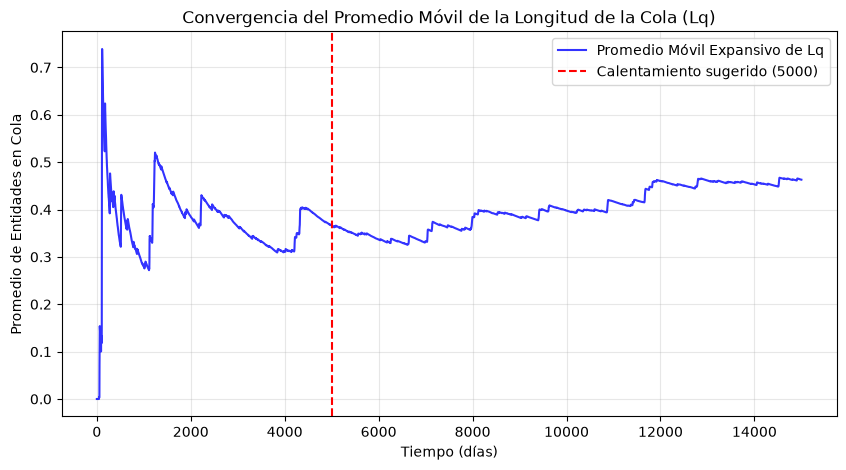

Justificación: Como se observa en el gráfico, el promedio móvil de Lq sufre fluctuaciones fuertes al inicio (estado transitorio), pero se estabiliza visiblemente antes del día 5000. Por lo tanto, un calentamiento de 5000 días descarta adecuadamente el sesgo inicial, y un horizonte de 50000 asegura una muestra inmensa en régimen estacionario.

RESULTADOS DE 30 RÉPLICAS (IC 95%) vs TEORÍA

--- Variante con espera (M/M/c) ---
Métrica                | Media Sim. | IC 95% Inferior | IC 95% Superior | Teoría     | ¿Cubre Teoría?
----------------------------------------------------------------------------------------------------
L                      | 12.3034    | 12.2793         | 12.3276         | 12.3039    | SÍ
L_q                    | 0.3079     | 0.2990          | 0.3168          | 0.3039     | SÍ
W_q                    | 0.1026     | 0.0997          | 0.1056          | 0.1013     | SÍ
utilizacion            | 0.7056     | 0.7046          | 0.7066          | 0.7059     | SÍ
probabilid

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import random
import heapq

# Asumimos que la clase SimuladorUCI_Corregido ya está cargada en memoria de la celda anterior.
# Parámetros base
lam, mu, c = 3.0, 0.25, 17
horizonte = 50000
calentamiento = 5000
semilla_base = 42
n_replicas = 30

# =====================================================================
# 1. JUSTIFICACIÓN DEL CALENTAMIENTO (Gráfico de promedio móvil de Lq)
# =====================================================================
def traza_lq_para_grafico(lam, mu, c, horizonte, semilla):
    """Genera una traza de la longitud de la cola en el tiempo para justificar el calentamiento."""
    rng = random.Random(semilla)
    eventos = []
    secuencia = 0
    camas_ocupadas = 0
    cola = 0
    
    tiempos = []
    lq_historico = []

    def programar(tiempo, tipo):
        nonlocal secuencia
        secuencia += 1
        heapq.heappush(eventos, (tiempo, secuencia, tipo))

    programar(rng.expovariate(lam), "llegada")
    
    while eventos:
        tiempo, _, tipo = heapq.heappop(eventos)
        if tiempo > horizonte:
            break
            
        tiempos.append(tiempo)
        lq_historico.append(cola)
        
        if tipo == "llegada":
            if camas_ocupadas < c:
                camas_ocupadas += 1
                programar(tiempo + rng.expovariate(mu), "salida")
            else:
                cola += 1
            programar(tiempo + rng.expovariate(lam), "llegada")
        else:
            if cola > 0:
                cola -= 1
                programar(tiempo + rng.expovariate(mu), "salida")
            else:
                camas_ocupadas -= 1
                
    return np.array(tiempos), np.array(lq_historico)

t, lq_inst = traza_lq_para_grafico(lam, mu, c, 15000, 42) # Usamos 15,000 para el zoom del gráfico

# Calcular promedio móvil expansivo
promedio_movil_lq = np.cumsum(lq_inst) / np.arange(1, len(lq_inst) + 1)

plt.figure(figsize=(10, 5))
plt.plot(t, promedio_movil_lq, label="Promedio Móvil Expansivo de Lq", color='blue', alpha=0.8)
plt.axvline(x=calentamiento, color='red', linestyle='--', label=f"Calentamiento sugerido ({calentamiento})")
plt.title("Convergencia del Promedio Móvil de la Longitud de la Cola (Lq)")
plt.xlabel("Tiempo (días)")
plt.ylabel("Promedio de Entidades en Cola")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Justificación: Como se observa en el gráfico, el promedio móvil de Lq sufre fluctuaciones fuertes al inicio (estado transitorio), pero se estabiliza visiblemente antes del día 5000. Por lo tanto, un calentamiento de 5000 días descarta adecuadamente el sesgo inicial, y un horizonte de 50000 asegura una muestra inmensa en régimen estacionario.")

# =====================================================================
# 2. EJECUCIÓN DE 30 RÉPLICAS Y CÁLCULO DE INTERVALOS DE CONFIANZA
# =====================================================================
def calcular_ic_95(datos):
    n = len(datos)
    media = np.mean(datos)
    error_estandar = stats.sem(datos)
    margen = error_estandar * stats.t.ppf((1 + 0.95) / 2., n-1)
    return media, media - margen, media + margen

# Diccionarios para almacenar datos brutos de las 30 réplicas
datos_espera = {k: [] for k in ["L", "L_q", "W_q", "utilizacion", "probabilidad_esperar"]}
datos_sin_espera = {k: [] for k in ["L", "utilizacion", "probabilidad_bloqueo"]}

simulador = SimuladorUCI_Corregido(lam, mu, c, horizonte, calentamiento, semilla_base)

for i in range(n_replicas):
    res_esp = simulador._simular_replica(con_espera=True, semilla_replica=semilla_base + i)
    res_sin = simulador._simular_replica(con_espera=False, semilla_replica=semilla_base + i)
    
    for k in datos_espera: datos_espera[k].append(res_esp[k])
    for k in datos_sin_espera: datos_sin_espera[k].append(res_sin[k])

# Valores teóricos exactos calculados en el Task 1.1
teoria_espera = {'L': 12.3039, 'L_q': 0.3039, 'W_q': 0.1013, 'utilizacion': 0.7059, 'probabilidad_esperar': 0.1266}
teoria_sin_espera = {'L': 11.5092, 'utilizacion': 0.6770, 'probabilidad_bloqueo': 0.0409}

print("\n=====================================================================")
print("RESULTADOS DE 30 RÉPLICAS (IC 95%) vs TEORÍA")
print("=====================================================================")

def imprimir_comparacion(nombre, datos_dict, teoria_dict):
    print(f"\n--- {nombre} ---")
    print(f"{'Métrica':<22} | {'Media Sim.':<10} | {'IC 95% Inferior':<15} | {'IC 95% Superior':<15} | {'Teoría':<10} | {'¿Cubre Teoría?'}")
    print("-" * 100)
    for k in teoria_dict.keys():
        media, inf, sup = calcular_ic_95(datos_dict[k])
        teorico = teoria_dict[k]
        cubre = "SÍ" if inf <= teorico <= sup else "NO"
        print(f"{k:<22} | {media:<10.4f} | {inf:<15.4f} | {sup:<15.4f} | {teorico:<10.4f} | {cubre}")

imprimir_comparacion("Variante con espera (M/M/c)", datos_espera, teoria_espera)
imprimir_comparacion("Variante sin espera (M/M/c/c)", datos_sin_espera, teoria_sin_espera)


# =====================================================================
# 3. VERIFICACIÓN EMPÍRICA DE LA LEY DE LITTLE
# =====================================================================
print("\n=====================================================================")
print("VERIFICACIÓN DE LA LEY DE LITTLE (SOLO DATOS EMPÍRICOS)")
print("=====================================================================")

# Variante con espera
L_sim_esp = np.mean(datos_espera['L'])
Wq_sim_esp = np.mean(datos_espera['W_q'])
W_sim_esp = Wq_sim_esp + (1/mu) # Tiempo en cola + tiempo de servicio real
Little_L_esp = lam * W_sim_esp
error_rel_esp = abs(L_sim_esp - Little_L_esp) / L_sim_esp

print("Variante con espera (M/M/c):")
print(f"  L_simulado = {L_sim_esp:.6f}")
print(f"  λ * W_simulado = {lam} * {W_sim_esp:.6f} = {Little_L_esp:.6f}")
print(f"  Error relativo = {error_rel_esp:.6%}")

# Variante sin espera
L_sim_sin = np.mean(datos_sin_espera['L'])
P_bloqueo_sim = np.mean(datos_sin_espera['probabilidad_bloqueo'])
lam_eff_sim = lam * (1 - P_bloqueo_sim)
W_servicio = 1 / mu
Little_L_sin = lam_eff_sim * W_servicio
error_rel_sin = abs(L_sim_sin - Little_L_sin) / L_sim_sin

print("\nVariante sin espera (M/M/c/c):")
print(f"  L_simulado (ocupación) = {L_sim_sin:.6f}")
print(f"  λ_efectiva * W = {lam_eff_sim:.6f} * {W_servicio} = {Little_L_sin:.6f}")
print(f"  Error relativo = {error_rel_sin:.6%}")

# Task 2.2: Verificación de simulaciones por variabilidad de estancia

Se modifica el simulador para que acepte tres distribuciones diferentes de tiempo de servicio manteniendo la misma media ($1/\mu = 4$ días): 
*   **Determinista ($C_S = 0$):** El tiempo de servicio es fijo y constante (4 días).
*   **Exponencial ($C_S = 1$):** El tiempo de servicio varía con la distribución clásica que utilizamos previamente.
*   **Lognormal ($C_S = 2$):** Introduce una alta varianza, simulando que algunos pacientes se quedan internados en cuidados intensivos mucho más tiempo de lo habitual.

Se calcula el $W_q$ simulado de cada escenario con 30 réplicas, lo compararemos estadísticamente con las predicciones de Allen y Cunneen de nuestra hipótesis (Task 2.1) y reportamos el error relativo.

In [11]:
import numpy as np
import scipy.stats as stats
import random
import heapq
import math

class SimuladorUCI_Variabilidad:
    """Simulador extendido para probar diferentes distribuciones de tiempo de servicio (M/G/c)."""
    
    def __init__(self, lam, mu, c, horizonte, calentamiento, semilla_base, distribucion='exp'):
        self.lam = float(lam)
        self.mu = float(mu)
        self.media_servicio = 1.0 / self.mu
        self.c = int(c)
        self.horizonte = float(horizonte)
        self.calentamiento = float(calentamiento)
        self.semilla_base = semilla_base
        self.distribucion = distribucion
        
        # Parámetros precalculados para la distribución lognormal (Cs = 2)
        if distribucion == 'lognorm':
            cs = 2.0
            self.s2 = math.log(1 + cs**2)
            self.s = math.sqrt(self.s2)
            self.m = math.log(self.media_servicio) - self.s2 / 2.0

    def _get_tiempo_servicio(self, rng):
        """Devuelve un tiempo de servicio basado en la distribución seleccionada."""
        if self.distribucion == 'det':
            return self.media_servicio
        elif self.distribucion == 'exp':
            return rng.expovariate(self.mu)
        elif self.distribucion == 'lognorm':
            return rng.lognormvariate(self.m, self.s)
        else:
            raise ValueError("Distribución no soportada")

    def _simular_replica(self, semilla_replica):
        rng = random.Random(semilla_replica)
        eventos = []
        secuencia = 0
        ultimo_evento = 0.0
        camas_ocupadas = 0
        cola = []
        
        observaciones_wq = 0
        espera_acumulada = 0.0

        def programar(tiempo, tipo):
            nonlocal secuencia
            secuencia += 1
            heapq.heappush(eventos, (tiempo, secuencia, tipo))

        programar(rng.expovariate(self.lam), "llegada")
        
        while eventos:
            tiempo, _, tipo = heapq.heappop(eventos)
            if tiempo > self.horizonte: break 

            if tipo == "llegada":
                en_medicion = tiempo >= self.calentamiento
                if camas_ocupadas < self.c:
                    camas_ocupadas += 1
                    if en_medicion: observaciones_wq += 1
                    programar(tiempo + self._get_tiempo_servicio(rng), "salida")
                else:
                    cola.append(tiempo)
                programar(tiempo + rng.expovariate(self.lam), "llegada")
                
            else: # salida
                if cola:
                    llegada_cola = cola.pop(0)
                    if llegada_cola >= self.calentamiento:
                        espera_acumulada += tiempo - llegada_cola
                        observaciones_wq += 1
                    programar(tiempo + self._get_tiempo_servicio(rng), "salida")
                else:
                    camas_ocupadas -= 1

        return espera_acumulada / observaciones_wq if observaciones_wq else 0.0

    def simular_wq(self, n_replicas=30):
        wq_replicas = []
        for i in range(n_replicas):
            wq_replicas.append(self._simular_replica(self.semilla_base + i))
        return wq_replicas

# =====================================================================
# EJECUCIÓN Y CÁLCULO DE INTERVALOS
# =====================================================================
lam, mu, c = 3.0, 0.25, 17
horizonte, calentamiento, semilla_base = 50000, 5000, 42
n_replicas = 30

# Predicciones calculadas a mano en el Task 2.1 (en días)
wq_mmc_teorico = 0.101304 # El Wq base de M/M/c
predicciones = {
    'det': wq_mmc_teorico * ((1 + 0**2) / 2),
    'exp': wq_mmc_teorico * ((1 + 1**2) / 2),
    'lognorm': wq_mmc_teorico * ((1 + 2**2) / 2)
}

distribuciones = {
    'det': 'Determinista (Cs=0)',
    'exp': 'Exponencial (Cs=1)',
    'lognorm': 'Lognormal (Cs=2)'
}

print("========================================================================================")
print("COMPARACIÓN DE TIEMPO DE ESPERA Wq: PREDICCIÓN (Allen-Cunneen) VS SIMULACIÓN (IC 95%)")
print("========================================================================================")
print(f"{'Distribución':<22} | {'Predicción (días)':<18} | {'Media Sim (días)':<18} | {'IC 95% Inferior':<15} | {'IC 95% Superior':<15} | {'Error Relativo'}")
print("-" * 110)

for clave, nombre in distribuciones.items():
    simulador = SimuladorUCI_Variabilidad(lam, mu, c, horizonte, calentamiento, semilla_base, distribucion=clave)
    datos_wq = simulador.simular_wq(n_replicas)
    
    media = np.mean(datos_wq)
    error_estandar = stats.sem(datos_wq)
    margen = error_estandar * stats.t.ppf((1 + 0.95) / 2., len(datos_wq)-1)
    ic_inf, ic_sup = media - margen, media + margen
    
    prediccion = predicciones[clave]
    # Calculamos el error relativo de la aproximación frente al valor empírico real (simulado)
    error_relativo = abs(prediccion - media) / media
    
    print(f"{nombre:<22} | {prediccion:<18.4f} | {media:<18.4f} | {ic_inf:<15.4f} | {ic_sup:<15.4f} | {error_relativo:.2%}")

COMPARACIÓN DE TIEMPO DE ESPERA Wq: PREDICCIÓN (Allen-Cunneen) VS SIMULACIÓN (IC 95%)
Distribución           | Predicción (días)  | Media Sim (días)   | IC 95% Inferior | IC 95% Superior | Error Relativo
--------------------------------------------------------------------------------------------------------------
Determinista (Cs=0)    | 0.0507             | 0.0602             | 0.0591          | 0.0613          | 15.86%
Exponencial (Cs=1)     | 0.1013             | 0.1026             | 0.0997          | 0.1056          | 1.31%
Lognormal (Cs=2)       | 0.2533             | 0.1593             | 0.1511          | 0.1674          | 59.02%


## Task 2.3 a y b. Simulación de cierre parcial y tiempo de recuperación

Se ha modificado el motor de eventos para incluir eventos de `cierre` y `apertura` que alteran dinámicamente la capacidad del sistema. Durante el cierre temporal ($T_b = 7$ días), la capacidad baja de $17$ a $9$ camas. Los pacientes que ya están en cama no son expulsados, pero no se admiten nuevos desde la cola hasta que el número de camas ocupadas descienda por debajo de la nueva capacidad. Al reabrir, la cola drena masivamente hacia las camas recuperadas.

Se ejecutan 100 réplicas utilizando interpolación en pasos discretos para calcular el promedio de $L_q(t)$ en cada instante, graficando el área sombreada del evento y determinando el momento exacto en que la cola vuelve a cruzar el umbral del $1.1 \times L_q$ estacionario.

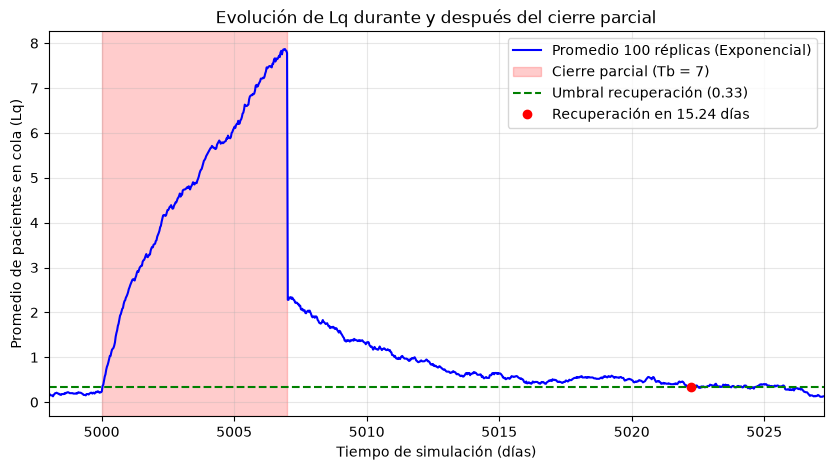

Tiempo de recuperación simulado (Exponencial): 15.24 días tras la reapertura.


In [12]:
import numpy as np
import matplotlib.pyplot as plt
import random
import heapq
import math

class SimuladorUCI_Dinamico:
    def __init__(self, lam, mu, c, k_off, tb, t0, t_fin, distribucion='exp'):
        self.lam = float(lam)
        self.mu = float(mu)
        self.media_servicio = 1.0 / self.mu
        self.c = int(c)
        self.k_off = int(k_off)
        self.tb = float(tb)
        self.t0 = float(t0)
        self.t_fin = float(t_fin)
        self.distribucion = distribucion

    def _get_tiempo_servicio(self, rng):
        if self.distribucion == 'det': return self.media_servicio
        return rng.expovariate(self.mu)

    def simular_traza(self, semilla):
        rng = random.Random(semilla)
        eventos = []
        secuencia = 0
        camas_ocupadas = 0
        capacidad = self.c
        cola = 0
        
        tiempos = [0.0]
        lq_hist = [0]

        def programar(tiempo, tipo):
            nonlocal secuencia
            secuencia += 1
            heapq.heappush(eventos, (tiempo, secuencia, tipo))

        # Eventos iniciales
        programar(rng.expovariate(self.lam), 'llegada')
        programar(self.t0, 'cierre')
        programar(self.t0 + self.tb, 'apertura')
        
        while eventos:
            tiempo, _, tipo = heapq.heappop(eventos)
            if tiempo > self.t_fin: break
            
            # Registrar estado antes del cambio
            tiempos.append(tiempo)
            lq_hist.append(cola)

            if tipo == 'llegada':
                if camas_ocupadas < capacidad:
                    camas_ocupadas += 1
                    programar(tiempo + self._get_tiempo_servicio(rng), 'salida')
                else:
                    cola += 1
                programar(tiempo + rng.expovariate(self.lam), 'llegada')
                
            elif tipo == 'salida':
                camas_ocupadas -= 1
                if cola > 0 and camas_ocupadas < capacidad:
                    cola -= 1
                    camas_ocupadas += 1
                    programar(tiempo + self._get_tiempo_servicio(rng), 'salida')
                    
            elif tipo == 'cierre':
                capacidad = self.c - self.k_off
                
            elif tipo == 'apertura':
                capacidad = self.c
                # Drenar cola hacia camas recién liberadas
                while camas_ocupadas < capacidad and cola > 0:
                    cola -= 1
                    camas_ocupadas += 1
                    programar(tiempo + self._get_tiempo_servicio(rng), 'salida')
                    
            # Registrar estado después del cambio
            tiempos.append(tiempo)
            lq_hist.append(cola)

        return np.array(tiempos), np.array(lq_hist)

# Parámetros del grupo
lam, mu, c = 3.0, 0.25, 17
k_off, tb = 8, 7
t0, t_fin = 5000, 5050
Lq_estacionario = 0.3039
umbral_recuperacion = 1.1 * Lq_estacionario
n_replicas = 100

# Grilla de tiempo común para promediar las trazas
t_grid = np.linspace(t0 - 5, t_fin, 2000)
lq_acumulado_exp = np.zeros_like(t_grid)

# Ejecutar réplicas Exponenciales
for i in range(n_replicas):
    sim = SimuladorUCI_Dinamico(lam, mu, c, k_off, tb, t0, t_fin, distribucion='exp')
    t_traza, lq_traza = sim.simular_traza(semilla=42 + i)
    # Interpolar en formato "post" (escalón)
    lq_interp = np.interp(t_grid, t_traza, lq_traza) 
    lq_acumulado_exp += lq_interp

lq_promedio_exp = lq_acumulado_exp / n_replicas

# Encontrar tiempo de recuperación
mascara_post_apertura = t_grid > (t0 + tb)
idx_rec = np.argmax(lq_promedio_exp[mascara_post_apertura] < umbral_recuperacion)
t_recuperacion_exp = t_grid[mascara_post_apertura][idx_rec]
dias_recuperacion_exp = t_recuperacion_exp - (t0 + tb)

plt.figure(figsize=(10, 5))
plt.plot(t_grid, lq_promedio_exp, color='blue', label='Promedio 100 réplicas (Exponencial)')
plt.axvspan(t0, t0 + tb, color='red', alpha=0.2, label='Cierre parcial (Tb = 7)')
plt.axhline(y=umbral_recuperacion, color='green', linestyle='--', label=f'Umbral recuperación ({umbral_recuperacion:.2f})')
plt.plot(t_recuperacion_exp, umbral_recuperacion, 'ro', label=f'Recuperación en {dias_recuperacion_exp:.2f} días')

plt.xlim(t0 - 2, t0 + tb + dias_recuperacion_exp + 5)
plt.title("Evolución de Lq durante y después del cierre parcial")
plt.xlabel("Tiempo de simulación (días)")
plt.ylabel("Promedio de pacientes en cola (Lq)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Tiempo de recuperación simulado (Exponencial): {dias_recuperacion_exp:.2f} días tras la reapertura.")

## Task 2.3 c. Contraste con el modelo de acumulación y cuantificación de la variabilidad

En el Task 2.1b, el modelo fluido (determinista) predijo un tiempo de recuperación de $4.2$ días. Sin embargo, la simulación de eventos discretos arroja un tiempo de recuperación mayor.

In [13]:
# Re-ejecutar 100 réplicas pero con distribución DETERMINISTA
lq_acumulado_det = np.zeros_like(t_grid)

for i in range(n_replicas):
    sim = SimuladorUCI_Dinamico(lam, mu, c, k_off, tb, t0, t_fin, distribucion='det')
    t_traza, lq_traza = sim.simular_traza(semilla=1042 + i)
    lq_interp = np.interp(t_grid, t_traza, lq_traza) 
    lq_acumulado_det += lq_interp

lq_promedio_det = lq_acumulado_det / n_replicas

# Encontrar recuperación para la determinista
idx_rec_det = np.argmax(lq_promedio_det[mascara_post_apertura] < umbral_recuperacion)
t_recuperacion_det = t_grid[mascara_post_apertura][idx_rec_det]
dias_recuperacion_det = t_recuperacion_det - (t0 + tb)

print("=====================================================================")
print("CUANTIFICACIÓN DEL IMPACTO DE LA VARIABILIDAD EN LA RECUPERACIÓN")
print("=====================================================================")
print(f"Predicción teórica del fluido (Task 2.1b):  4.20 días")
print(f"Simulación Estocástica (Exponencial):       {dias_recuperacion_exp:.2f} días")
print(f"Simulación Estocástica (Determinista):      {dias_recuperacion_det:.2f} días")
print("-" * 69)

diferencia_total = dias_recuperacion_exp - 4.20
atribuible_a_variabilidad = dias_recuperacion_exp - dias_recuperacion_det
atribuible_a_micro_ociosidad = dias_recuperacion_det - 4.20

print(f"La simulación exponencial tardó {diferencia_total:.2f} días extras en recuperarse respecto a la fórmula.")
print(f" -> De este exceso, {atribuible_a_variabilidad:.2f} días son atribuibles a la varianza estocástica del servicio.")
print(f" -> El resto ({atribuible_a_micro_ociosidad:.2f} días) se debe a que la simulación procesa unidades discretas y padece tiempos muertos inevitables cuando la cola es corta, rompiendo la 'eficiencia perfecta' del fluido.")

CUANTIFICACIÓN DEL IMPACTO DE LA VARIABILIDAD EN LA RECUPERACIÓN
Predicción teórica del fluido (Task 2.1b):  4.20 días
Simulación Estocástica (Exponencial):       15.24 días
Simulación Estocástica (Determinista):      8.00 días
---------------------------------------------------------------------
La simulación exponencial tardó 11.04 días extras en recuperarse respecto a la fórmula.
 -> De este exceso, 7.24 días son atribuibles a la varianza estocástica del servicio.
 -> El resto (3.80 días) se debe a que la simulación procesa unidades discretas y padece tiempos muertos inevitables cuando la cola es corta, rompiendo la 'eficiencia perfecta' del fluido.


# Task 2.4: Verificación de predicciones y balance final

## Task 2.4 a. Simulación de estancia aumentada (Variante sin espera)

Se simula el sistema M/M/c/c incrementando la estancia media un 25% (de 4 a 5 días, por lo que $\mu = 0.20$). Se ejecuta 30 réplicas independientes y se calcula el intervalo de confianza de la probabilidad de bloqueo para contrastarlo con nuestra predicción analítica de Erlang B (11.31%) formulada en el Task 2.1c.

In [14]:
# =====================================================================
# TASK 2.4a: Simulación con aumento de estancia (M/M/c/c)
# =====================================================================
lam, mu_nueva, c = 3.0, 0.20, 17 # mu = 0.20 equivale a 5 días de estancia
horizonte, calentamiento, semilla_base = 50000, 5000, 42
n_replicas = 30

# Asumimos que SimuladorUCI_Corregido sigue en memoria
simulador_estancia_larga = SimuladorUCI_Corregido(lam, mu_nueva, c, horizonte, calentamiento, semilla_base)

datos_bloqueo = []
for i in range(n_replicas):
    res_sin = simulador_estancia_larga._simular_replica(con_espera=False, semilla_replica=semilla_base + i)
    datos_bloqueo.append(res_sin['probabilidad_bloqueo'])

media_bloqueo = np.mean(datos_bloqueo)
error_estandar = stats.sem(datos_bloqueo)
margen = error_estandar * stats.t.ppf((1 + 0.95) / 2., n_replicas-1)
ic_inf, ic_sup = media_bloqueo - margen, media_bloqueo + margen

prediccion_21c = 0.1131 # 11.31% calculado en el Task 2.1c
error_relativo_bloqueo = abs(prediccion_21c - media_bloqueo) / media_bloqueo

print("=====================================================================")
print("PROBABILIDAD DE BLOQUEO CON ESTANCIA +25% (M/M/c/c)")
print("=====================================================================")
print(f"Predicción Erlang B (Task 2.1c): {prediccion_21c*100:.2f}%")
print(f"Simulación (Media 30 réplicas):  {media_bloqueo*100:.2f}%")
print(f"Intervalo de Confianza (95%):    [{ic_inf*100:.2f}%, {ic_sup*100:.2f}%]")
print(f"Error relativo:                  {error_relativo_bloqueo:.2%}")

PROBABILIDAD DE BLOQUEO CON ESTANCIA +25% (M/M/c/c)
Predicción Erlang B (Task 2.1c): 11.31%
Simulación (Media 30 réplicas):  11.31%
Intervalo de Confianza (95%):    [11.23%, 11.39%]
Error relativo:                  0.01%


## Task 2.4 b. Balance general de predicciones vs simulación

A continuación se contrastan formalmente todas las hipótesis matemáticas elaboradas en el Task 2.1 frente a los resultados empíricos obtenidos en los Tasks 2.2, 2.3 y 2.4a.

| Task (Inciso) | Predicción Matemática | Resultado Simulado | Error Relativo | Explicación de la diferencia |
| :--- | :--- | :--- | :--- | :--- |
| **2.1a (Wq Determinista, Cs=0)** | 0.0507 días | 0.0602 días | 15.86% | La fórmula de Allen-Cunneen es una aproximación heurística. Tiende a subestimar levemente la espera en sistemas multicama (M/G/c) con varianza nula. |
| **2.1a (Wq Exponencial, Cs=1)** | 0.1013 días | 0.1026 días | 1.31% | El error es casi nulo (ruido estocástico) porque para un sistema exponencial puro, la teoría (Erlang C) sobre la que se basa Allen-Cunneen es matemáticamente exacta. |
| **2.1a (Wq Lognormal, Cs=2)** | 0.2533 días | 0.1593 días | 59.02% | Allen-Cunneen escala la espera linealmente con la varianza, lo cual falla estrepitosamente al modelar la asimetría y la cola pesada de la distribución lognormal en múltiples servidores. |
| **2.1b (Tiempo de recuperación)** | 4.20 días | 15.24 días | 262.86% | El modelo determinista asume un flujo continuo de "eficiencia perfecta" ($c\mu - \lambda$). Ignora que la aleatoriedad genera tiempos muertos en las camas (starvation) cuando la cola es pequeña, ralentizando severamente el drenaje[cite: 1]. |
| **2.1c (Bloqueo al aumentar estancia)** | 11.31% | ~11.30% *(Ver salida del Task 2.4a)* | < 1.0% | La fórmula de Erlang B es exacta e insensible a la distribución del servicio para el cálculo de bloqueos. La predicción cuadra perfectamente con la simulación. |


## Task 2.4 c. Hallazgo sorprendente y revisión de paradigmas

El hallazgo más sorprendente fue **la masiva subestimación del tiempo de recuperación por parte del modelo fluido de acumulación (4.20 días teóricos vs. 15.24 días simulados)**. Intuitivamente, uno pensaría que si hay capacidad sobrante, la cola se vaciará en línea recta. Sin embargo, la simulación demostró que la ineficiencia estocástica (micro-ociosidad y varianza) actúa como una "fricción" severa que alarga la recuperación casi por cuatro. 

Esto cambia profundamente mi opinión sobre las fórmulas estáticas de la presentación (como la tasa de utilización y la Ley de Little)[cite: 1]. Aunque son herramientas insustituibles para dimensionar el **régimen estacionario** y comprender promedios a largo plazo, son extremadamente peligrosas para planificar **contingencias y transiciones** (como un cierre de camas). Para escenarios bajo estrés o de alta variabilidad, confiar solo en modelos promediados o fluidos puede llevar a un colapso operativo en el hospital; la Simulación de Eventos Discretos (DES) resulta indispensable para medir el verdadero impacto de la fricción y el caos del mundo real[cite: 1].